# $K\alpha$ iron line profile just Schwarzschild case
# Flux with keV distribution 

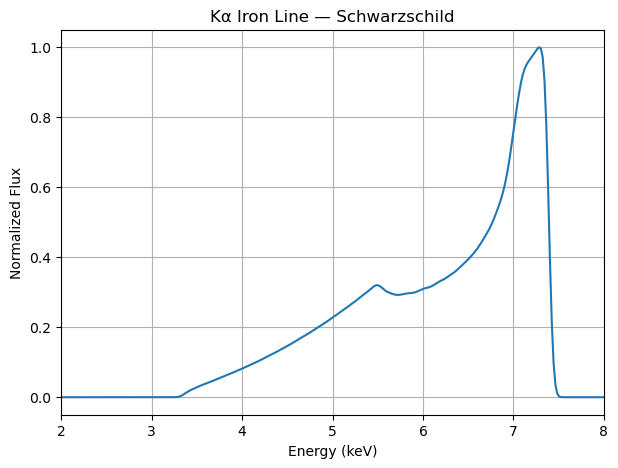

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# =========================
# 1. Physical parameters
# =========================

M = 1.0                  # black hole mass (geometric units)
E0 = 6.4                 # rest-frame iron line energy (keV)

incl_deg = 60            # inclination angle (degrees)
incl = np.deg2rad(incl_deg)

r_isco = 6*M             # ISCO for Schwarzschild
r_out = 50*M             # outer disk radius

# higher resolution (important for smoothness)
Nr = 700
Nphi = 700

q = 2                    # emissivity index

# =========================
# 2. Disk grid
# =========================

r = np.linspace(r_isco, r_out, Nr)
phi = np.linspace(0, 2*np.pi, Nphi)

R, PHI = np.meshgrid(r, phi)

# =========================
# 3. Orbital quantities
# =========================

def Omega(r):
    return np.sqrt(M / r**3)

# =========================
# 4. Photon impact parameter
# =========================

lambda_ph = R * np.sin(incl) * np.cos(PHI)

# =========================
# 5. Redshift factor g
# =========================

g = np.sqrt(1 - 3*M/R) / (1 - Omega(R)*lambda_ph)
g[g <= 0] = np.nan

# =========================
# 6. Emissivity profile
# =========================

Ie = R**(-q)

Eobs = g * E0
weights = (g**3) * Ie

# flatten arrays
Eobs_flat = Eobs.flatten()
weights_flat = weights.flatten()

mask = ~np.isnan(Eobs_flat)
Eobs_flat = Eobs_flat[mask]
weights_flat = weights_flat[mask]

# =========================
# 7. Histogram (2–10 keV)
# =========================

Emin, Emax = 2, 10
Nbins = 400

bins = np.linspace(Emin, Emax, Nbins)
spectrum, edges = np.histogram(Eobs_flat, bins=bins, weights=weights_flat)

Ecenters = 0.5*(edges[1:] + edges[:-1])

# =========================
# 8. Smooth spectrum
# =========================

spectrum = gaussian_filter1d(spectrum, sigma=2)

# normalize
spectrum = spectrum / np.max(spectrum)

# =========================
# 9. Plot
# =========================

plt.figure(figsize=(7,5))
plt.plot(Ecenters, spectrum)
plt.xlim(2, 8)

plt.xlabel("Energy (keV)")
plt.ylabel("Normalized Flux")
plt.title("Kα Iron Line — Schwarzschild")
plt.grid()

plt.show()

# Flux with g (redshift factor) dependence

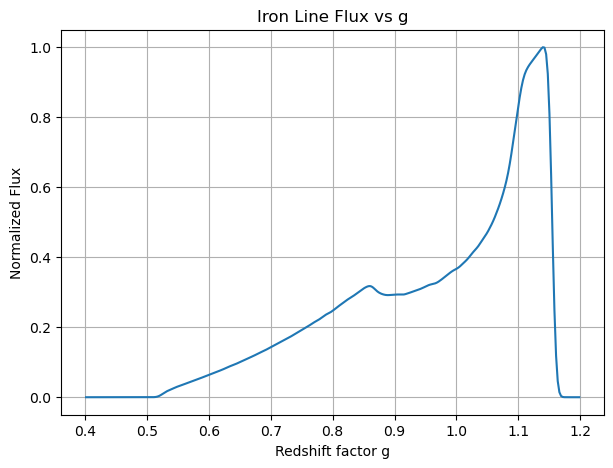

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# -----------------------------
# assume you already have
# Eobs_flat and weights_flat
# -----------------------------
# compute g from E_obs
E0 = 6.4
g_flat = Eobs_flat / E0

# -----------------------------
# histogram in g-space
# -----------------------------
gmin, gmax = 0.4, 1.2   # typical range for Schwarzschild
Nbins_g = 300

bins_g = np.linspace(gmin, gmax, Nbins_g)
flux_g, edges_g = np.histogram(g_flat, bins=bins_g, weights=weights_flat)
g_centers = 0.5*(edges_g[1:] + edges_g[:-1])

# smooth
flux_g = gaussian_filter1d(flux_g, sigma=2)

# normalize
flux_g /= flux_g.max()

# -----------------------------
# plot
# -----------------------------
plt.figure(figsize=(7,5))
plt.plot(g_centers, flux_g)
plt.xlabel("Redshift factor g")
plt.ylabel("Normalized Flux")
plt.title("Iron Line Flux vs g")
plt.grid()
plt.show()

# Finding the ISCO position codes

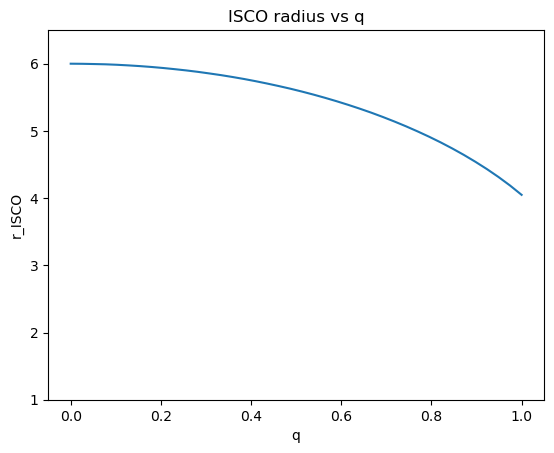

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

# -------- Metric function --------
def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r

# -------- find root automatically --------
def find_isco(q):
    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):
        if vals[i]*vals[i+1] < 0:
            sol = root_scalar(isco_eq, args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])
            return sol.root

    return np.nan  # agar topilmasa

# -------- compute --------
q_vals = np.linspace(0, 1., 40)
isco_vals = [find_isco(q) for q in q_vals]

# -------- plot --------
plt.figure()
plt.plot(q_vals, isco_vals)
plt.xlabel("q")
plt.ylabel("r_ISCO")
plt.ylim(1,6.5)
plt.title("ISCO radius vs q")
plt.show()

# Accretion disk's radiative flux with radial dependence 

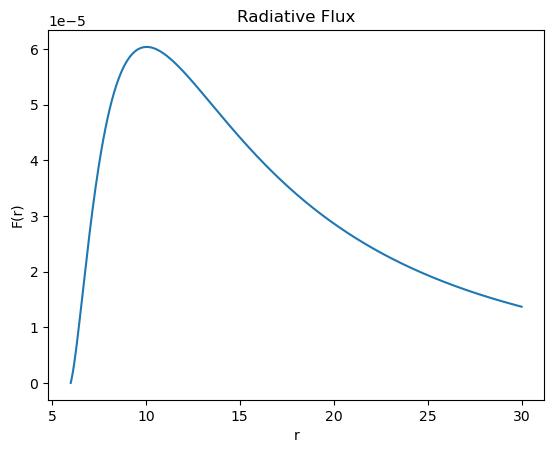

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid

# ---------- metric ----------
def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

# ---------- orbital quantities ----------
def Omega(r, q):
    return np.sqrt(df(r,q)/(2*r))

def E(r, q):
    fr = f(r,q)
    Om = Omega(r,q)
    return fr/np.sqrt(fr - r**2*Om**2)

def L(r, q):
    Om = Omega(r,q)
    return r**2*Om/np.sqrt(f(r,q) - r**2*Om**2)

def dL(r, q):
    h = 1e-4
    return (L(r+h,q) - L(r-h,q))/(2*h)

# ---------- radius grid ----------
q = 0.3
r = np.linspace(6,30,600)   # ISCO ~6 dan boshlash

E_vals = E(r,q)
L_vals = L(r,q)
Om_vals = Omega(r,q)

integrand = (E_vals - Om_vals*L_vals) * dL(r,q)

# integral from ISCO outward
I = cumulative_trapezoid(integrand, r, initial=0)

flux =  (df(r,q)/(4*np.pi*r)) * I / (E_vals - Om_vals*L_vals)**2

# ---------- plot ----------
plt.figure()
plt.plot(r, flux)
plt.xlabel("r")
plt.ylabel("F(r)")
plt.title("Radiative Flux")
plt.show()

# Einstein-Bronnikov spacetime
### $\mathcal{S} = \int d^4x \sqrt{-g}(R-L(F)),\quad R = g^{\sigma\rho}R_{\sigma\rho}$
### where  $L(F) = F \cosh^{-2}{[a(F/2)^{1/4}]},\quad F=F_{\mu\nu}F^{\mu\nu}$
#### $a = q_m^{3/2}/2m$ magnetic charge parameter
### $f(r) = 1 - \frac{2M}{r} \left(1 - \tanh{\frac{q^2}{(2 M r)}}\right)$

q = 0, ISCO = 6.00M
q = 0.4, ISCO = 5.75M
q = 0.8, ISCO = 4.90M


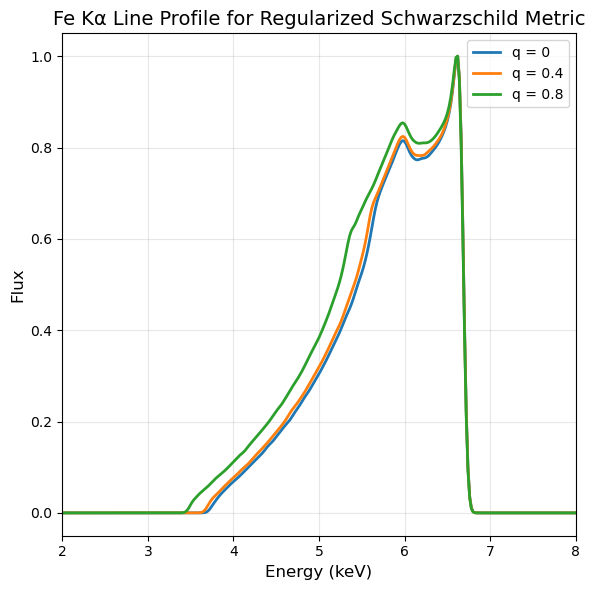

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar

# =========================
# GLOBAL PARAMETERS
# =========================

M = 1.0
E0 = 6.4
incl = np.deg2rad(30)

r_out = 100*M

Nr = 500
Nphi = 500
k = 2  # I \simeq r^(-k)

# Regularization parameters
q_values = [0, 0.4, 0.8]  # Different regularization strengths

# =========================
# REGULARIZED SCHWARZSCHILD METRIC FUNCTIONS
# =========================
# -------- Metric function --------
def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r

# -------- find root automatically --------

def get_isco(q):
    """
    Calculate ISCO for regularized Schwarzschild metric
    For standard Schwarzschild (zeta=0), ISCO = 6M
    For regularized metrics, ISCO decreases with increasing regularization
    """
    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):
        if vals[i]*vals[i+1] < 0:
            sol = root_scalar(isco_eq, args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])
            return sol.root

    return np.nan  # agar topilmasa


def metric_function(r, q):
    """
    Regularized Schwarzschild metric function f(r) = -g_tt
    
    Common regularization forms:
    1. Bardeen: f(r) = 1 - 2Mr^2/(r^3 + 2M l^2)^(3/2)
    2. Hayward: f(r) = 1 - 2Mr^2/(r^3 + 2M l^2)
    3. Simpson-Visser: f(r) = 1 - 2M/sqrt(r^2 + l^2)
    
    Here we'll implement a simple regularization:
    f(r) = 1 - 2M/√(r^2 + ζ^2)
    """
    if q == 0:
        # Standard Schwarzschild
        return 1 - 2*M/r
    else:
        # Regularized version (Simpson-Visser type)
        # This avoids the singularity at r=0
        return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def metric_derivative(r, q):
    """Numerical derivative of metric function"""
    h = 1e-5
    return (f(r+h, q) - f(r-h, q))/(2*h)

def keplerian_omega(r, q):
    """
    Keplerian angular velocity for regularized metric
    For circular orbits: Ω² = (df/dr)/(2r)
    """
    return np.sqrt(metric_derivative(r, q)/(2*r))

def impact_parameter(r, phi, incl, q):
    """
    Calculate impact parameter for ray tracing
    In a simple approximation, this is just r sin(incl) cos(phi)
    But for accurate results, you need full ray tracing
    """
    return r * np.sin(incl) * np.cos(phi)

# =========================
# LOOP OVER q
# =========================

plt.figure(figsize=(6, 6))

for q in q_values:
    
    # Calculate ISCO for this zeta
    r_isco = get_isco(q)
    print(f"q = {q}, ISCO = {r_isco:.2f}M")
    
    # Create grid from ISCO to outer radius
    r = np.linspace(r_isco, r_out, Nr)
    phi = np.linspace(0, 2*np.pi, Nphi)
    R, PHI = np.meshgrid(r, phi)
    
    # Calculate impact parameter (simplified)
    lambda_ph = impact_parameter(R, PHI, incl, q)
    
    # Calculate redshift factor
    Omega = keplerian_omega(R, q)
    f_r = metric_function(R, q)
    
    # Redshift formula for a general stationary metric
    # g = sqrt(-g_tt - 2Ω g_tφ - Ω² g_φφ) / (1 + Ω λ)
    # For non-rotating metric, g_tφ = 0 and g_φφ = r²
    numerator = np.sqrt(f_r - R**2 * Omega**2)
    denominator = 1 - Omega * lambda_ph  # Note sign: 1 - Ωλ for direct orbits
    g = numerator / denominator
    
    # Handle unphysical values
    g[g <= 0] = np.nan
    g[~np.isfinite(g)] = np.nan
    
    # Emissivity profile
    Ie = R**(-k)
    
    # Observed energy and flux
    Eobs = g * E0
    weights = (g**3) * Ie
    
    # Flatten and remove NaNs
    Eobs_flat = Eobs.flatten()
    weights_flat = weights.flatten()
    mask = ~np.isnan(Eobs_flat) & ~np.isnan(weights_flat)
    Eobs_clean = Eobs_flat[mask]
    weights_clean = weights_flat[mask]
    
    # Create spectrum
    bins = np.linspace(2, 10, 400)
    spec, edges = np.histogram(Eobs_clean, bins=bins, weights=weights_clean)
    Ecent = 0.5*(edges[1:] + edges[:-1])
    
    # Smooth and normalize
    spec = gaussian_filter1d(spec, sigma=2)
    if spec.max() > 0:
        spec /= spec.max()
    
    plt.plot(Ecent, spec, linewidth=2, label=f"q = {q}")

# =========================
# PLOT
# =========================

plt.xlabel("Energy (keV)", fontsize=12)
plt.ylabel("Flux", fontsize=12)
plt.title("Fe Kα Line Profile for Regularized Schwarzschild Metric", fontsize=14)
plt.xlim(2, 8)
plt.legend(fontsize=10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("IronLineGraph.pdf", format='pdf')
plt.show()

## $I_e \sim r^{-\alpha}$
## where $\alpha$ is emmisivity index

## $\alpha=3$ and the inclination angle $i=\pi/6$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar

# =========================
# GLOBAL PARAMETERS
# =========================

M = 1.0
incl = np.deg2rad(30)

r_out = 30*M

Nr = 500
Nphi = 500
k = 3  # emissivity index

q_values = [0, 0.3, 0.6]

# =========================
# METRIC FUNCTIONS
# =========================

def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r


# =========================
# FIND ISCO
# =========================

def get_isco(q):

    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):

        if vals[i]*vals[i+1] < 0:

            sol = root_scalar(isco_eq,
                              args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])

            return sol.root

    return np.nan


# =========================
# ORBITAL PROPERTIES
# =========================

def metric_derivative(r, q):

    h = 1e-5
    return (f(r+h, q) - f(r-h, q))/(2*h)


def keplerian_omega(r, q):

    return np.sqrt(metric_derivative(r, q)/(2*r))


def impact_parameter(r, phi, incl):

    return r * np.sin(incl) * np.cos(phi)


# =========================
# PLOT
# =========================

plt.figure(figsize=(6,6))

for q in q_values:

    r_isco = get_isco(q)

    print(f"q = {q}, ISCO = {r_isco:.2f} M")

    r = np.linspace(r_isco, r_out, Nr)
    phi = np.linspace(0, 2*np.pi, Nphi)

    R, PHI = np.meshgrid(r, phi)

    lam = impact_parameter(R, PHI, incl)

    Omega = keplerian_omega(R, q)

    f_r = f(R, q)

    # redshift factor
    numerator = np.sqrt(f_r - R**2 * Omega**2)
    denominator = 1 - Omega * lam

    g = numerator / denominator

    g[g <= 0] = np.nan
    g[~np.isfinite(g)] = np.nan

    # emissivity
    Ie = R**(-k)

    weights = g**3 * Ie

    g_flat = g.flatten()
    weights_flat = weights.flatten()

    mask = ~np.isnan(g_flat) & ~np.isnan(weights_flat)

    g_clean = g_flat[mask]
    weights_clean = weights_flat[mask]

    # histogram
    bins = np.linspace(0, 1.3, 400)

    spec, edges = np.histogram(g_clean,
                               bins=bins,
                               weights=weights_clean)

    gcent = 0.5*(edges[1:] + edges[:-1])

    spec = gaussian_filter1d(spec, sigma=2)

    if spec.max() > 0:
        spec /= spec.max()

    plt.plot(gcent, spec,
             linewidth=2,
             label=f"q = {q}")

# =========================
# FINAL GRAPH
# =========================

plt.xlabel("g", fontsize=12)
plt.ylabel("Flux", fontsize=12)
#plt.title("Redshift Factor Distribution from Accretion Disk", fontsize=14)
plt.xlim(0.4,1.3)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("g_distribution3inc30.pdf")
plt.show()

ModuleNotFoundError: No module named 'numpy'

q = 0, ISCO = 6.00 M
q = 0.3, ISCO = 5.86 M
q = 0.6, ISCO = 5.42 M


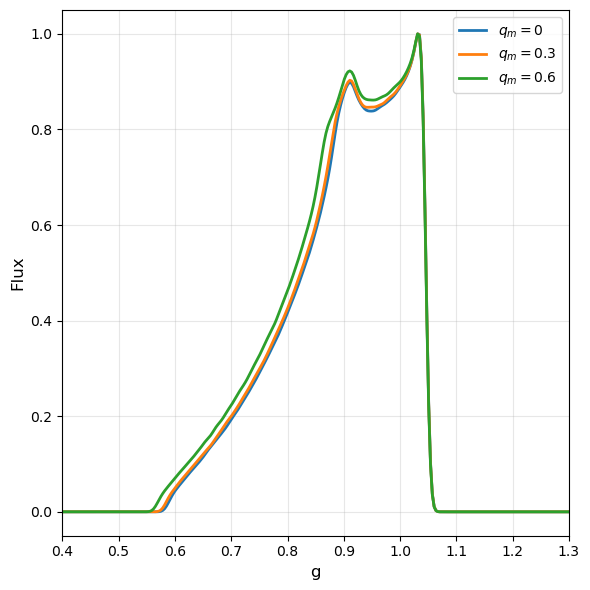

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar

# =========================
# GLOBAL PARAMETERS
# =========================

M = 1.0
incl = np.deg2rad(30)

r_out = 60*M

Nr = 500
Nphi = 500
k = 2  # emissivity index

q_values = [0, 0.3, 0.6]

# =========================
# METRIC FUNCTIONS
# =========================

def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r


# =========================
# FIND ISCO
# =========================

def get_isco(q):

    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):

        if vals[i]*vals[i+1] < 0:

            sol = root_scalar(isco_eq,
                              args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])

            return sol.root

    return np.nan


# =========================
# ORBITAL PROPERTIES
# =========================

def metric_derivative(r, q):

    h = 1e-5
    return (f(r+h, q) - f(r-h, q))/(2*h)


def keplerian_omega(r, q):

    return np.sqrt(metric_derivative(r, q)/(2*r))


def impact_parameter(r, phi, incl):

    return r * np.sin(incl) * np.cos(phi)


# =========================
# PLOT
# =========================

plt.figure(figsize=(6,6))

for q in q_values:

    r_isco = get_isco(q)

    print(f"q = {q}, ISCO = {r_isco:.2f} M")

    r = np.linspace(r_isco, r_out, Nr)
    phi = np.linspace(0, 2*np.pi, Nphi)

    R, PHI = np.meshgrid(r, phi)

    lam = impact_parameter(R, PHI, incl)

    Omega = keplerian_omega(R, q)

    f_r = f(R, q)

    # redshift factor
    numerator = np.sqrt(f_r - R**2 * Omega**2)
    denominator = 1 - Omega * lam

    g = numerator / denominator

    g[g <= 0] = np.nan
    g[~np.isfinite(g)] = np.nan

    # emissivity
    Ie = R**(-k)

    weights = g**3 * Ie

    g_flat = g.flatten()
    weights_flat = weights.flatten()

    mask = ~np.isnan(g_flat) & ~np.isnan(weights_flat)

    g_clean = g_flat[mask]
    weights_clean = weights_flat[mask]

    # histogram
    bins = np.linspace(0, 1.3, 400)

    spec, edges = np.histogram(g_clean,
                               bins=bins,
                               weights=weights_clean)

    gcent = 0.5*(edges[1:] + edges[:-1])

    spec = gaussian_filter1d(spec, sigma=2)

    if spec.max() > 0:
        spec /= spec.max()

    plt.plot(gcent, spec,
             linewidth=2,
             label=fr"$q_m = {q}$")

# =========================
# FINAL GRAPH
# =========================

plt.xlabel("g", fontsize=12)
plt.ylabel("Flux", fontsize=12)
#plt.title("Redshift Factor Distribution from Accretion Disk", fontsize=14)
plt.xlim(0.4,1.3)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("g_distribution2inc30.pdf")
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar

# =========================
# GLOBAL PARAMETERS
# =========================

M = 1.0
incl = np.deg2rad(45)

r_out = 60*M

Nr = 500
Nphi = 500
k = 2  # emissivity index

q_values = [0, 0.3, 0.6]

# =========================
# METRIC FUNCTIONS
# =========================

def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r


# =========================
# FIND ISCO
# =========================

def get_isco(q):

    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):

        if vals[i]*vals[i+1] < 0:

            sol = root_scalar(isco_eq,
                              args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])

            return sol.root

    return np.nan


# =========================
# ORBITAL PROPERTIES
# =========================

def metric_derivative(r, q):

    h = 1e-5
    return (f(r+h, q) - f(r-h, q))/(2*h)


def keplerian_omega(r, q):

    return np.sqrt(metric_derivative(r, q)/(2*r))


def impact_parameter(r, phi, incl):

    return r * np.sin(incl) * np.cos(phi)


# =========================
# PLOT
# =========================

plt.figure(figsize=(6,6))

for q in q_values:

    r_isco = get_isco(q)

    print(f"q = {q}, ISCO = {r_isco:.2f} M")

    r = np.linspace(r_isco, r_out, Nr)
    phi = np.linspace(0, 2*np.pi, Nphi)

    R, PHI = np.meshgrid(r, phi)

    lam = impact_parameter(R, PHI, incl)

    Omega = keplerian_omega(R, q)

    f_r = f(R, q)

    # redshift factor
    numerator = np.sqrt(f_r - R**2 * Omega**2)
    denominator = 1 - Omega * lam

    g = numerator / denominator

    g[g <= 0] = np.nan
    g[~np.isfinite(g)] = np.nan

    # emissivity
    Ie = R**(-k)

    weights = g**3 * Ie

    g_flat = g.flatten()
    weights_flat = weights.flatten()

    mask = ~np.isnan(g_flat) & ~np.isnan(weights_flat)

    g_clean = g_flat[mask]
    weights_clean = weights_flat[mask]

    # histogram
    bins = np.linspace(0, 1.3, 400)

    spec, edges = np.histogram(g_clean,
                               bins=bins,
                               weights=weights_clean)

    gcent = 0.5*(edges[1:] + edges[:-1])

    spec = gaussian_filter1d(spec, sigma=2)

    if spec.max() > 0:
        spec /= spec.max()

    plt.plot(gcent, spec,
             linewidth=2,
             label=fr"$q_m = {q}$")

# =========================
# FINAL GRAPH
# =========================

plt.xlabel("g", fontsize=12)
plt.ylabel("Flux", fontsize=12)
#plt.title("Redshift Factor Distribution from Accretion Disk", fontsize=14)
plt.xlim(0.4,1.3)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("g_distribution2inc45.pdf")
plt.show()

q = 0, ISCO = 6.00 M
q = 0.3, ISCO = 5.86 M
q = 0.6, ISCO = 5.42 M


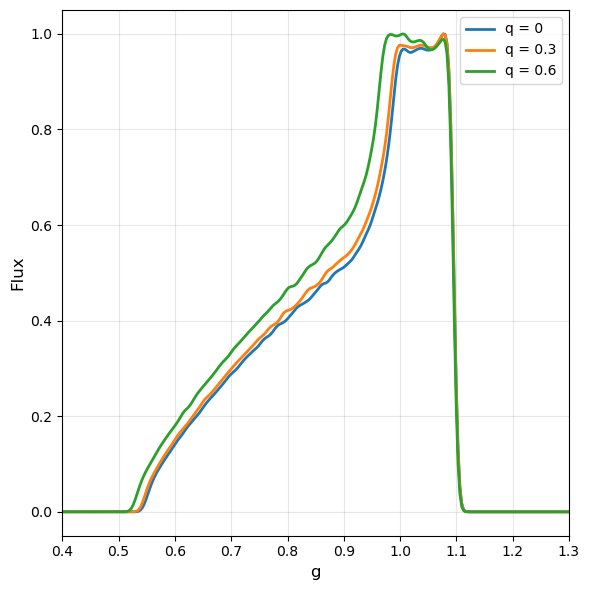

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import root_scalar

# =========================
# GLOBAL PARAMETERS
# =========================

M = 1.0
incl = np.deg2rad(45)

r_out = 60*M

Nr = 500
Nphi = 500
k = 3  # emissivity index

q_values = [0, 0.3, 0.6]

# =========================
# METRIC FUNCTIONS
# =========================

def f(r, q):
    return 1 - (2/r)*(1 - np.tanh(q**2/(2*r)))

def df(r, q, h=1e-6):
    return (f(r+h, q) - f(r-h, q))/(2*h)

def d2f(r, q, h=1e-5):
    return (f(r+h, q) - 2*f(r, q) + f(r-h, q))/h**2

def isco_eq(r, q):
    fr = f(r, q)
    dfr = df(r, q)
    d2fr = d2f(r, q)
    return 2*fr*d2fr - 4*(dfr**2) + 6*fr*dfr/r


# =========================
# FIND ISCO
# =========================

def get_isco(q):

    r_grid = np.linspace(3, 30, 400)

    vals = isco_eq(r_grid, q)

    for i in range(len(r_grid)-1):

        if vals[i]*vals[i+1] < 0:

            sol = root_scalar(isco_eq,
                              args=(q,),
                              bracket=[r_grid[i], r_grid[i+1]])

            return sol.root

    return np.nan


# =========================
# ORBITAL PROPERTIES
# =========================

def metric_derivative(r, q):

    h = 1e-5
    return (f(r+h, q) - f(r-h, q))/(2*h)


def keplerian_omega(r, q):

    return np.sqrt(metric_derivative(r, q)/(2*r))


def impact_parameter(r, phi, incl):

    return r * np.sin(incl) * np.cos(phi)


# =========================
# PLOT
# =========================

plt.figure(figsize=(6,6))

for q in q_values:

    r_isco = get_isco(q)

    print(f"q = {q}, ISCO = {r_isco:.2f} M")

    r = np.linspace(r_isco, r_out, Nr)
    phi = np.linspace(0, 2*np.pi, Nphi)

    R, PHI = np.meshgrid(r, phi)

    lam = impact_parameter(R, PHI, incl)

    Omega = keplerian_omega(R, q)

    f_r = f(R, q)

    # redshift factor
    numerator = np.sqrt(f_r - R**2 * Omega**2)
    denominator = 1 - Omega * lam

    g = numerator / denominator

    g[g <= 0] = np.nan
    g[~np.isfinite(g)] = np.nan

    # emissivity
    Ie = R**(-k)

    weights = g**3 * Ie

    g_flat = g.flatten()
    weights_flat = weights.flatten()

    mask = ~np.isnan(g_flat) & ~np.isnan(weights_flat)

    g_clean = g_flat[mask]
    weights_clean = weights_flat[mask]

    # histogram
    bins = np.linspace(0, 1.3, 400)

    spec, edges = np.histogram(g_clean,
                               bins=bins,
                               weights=weights_clean)

    gcent = 0.5*(edges[1:] + edges[:-1])

    spec = gaussian_filter1d(spec, sigma=2)

    if spec.max() > 0:
        spec /= spec.max()

    plt.plot(gcent, spec,
             linewidth=2,
             label=f"q = {q}")

# =========================
# FINAL GRAPH
# =========================

plt.xlabel("g", fontsize=12)
plt.ylabel("Flux", fontsize=12)
#plt.title("Redshift Factor Distribution from Accretion Disk", fontsize=14)
plt.xlim(0.4,1.3)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("g_distribution3inc45.pdf")
plt.show()

In [4]:
conda install numpy scipy matplotlib

Channels:
 - defaults
 - conda-forge
Platform: osx-arm64
Solving environment: done

## Package Plan ##

  environment location: /Users/bakhodir/miniforge3

  added / updated specs:
    - matplotlib
    - numpy
    - scipy


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    blas-1.0                   |         openblas          10 KB
    ca-certificates-2026.5.14  |       hca03da5_0         108 KB
    certifi-2026.5.20          |  py313hca03da5_0         131 KB
    conda-26.5.2               |  py313hca03da5_0         1.3 MB
    contourpy-1.3.3            |  py313h20e30b6_0        11.4 MB
    cycler-0.12.1              |  py313hca03da5_0          19 KB
    fonttools-4.62.1           |  py313haa24f5a_0         4.1 MB
    freetype-2.14.1            |       h7cdc921_0         589 KB
    jpeg-9f                    |       h2f69dba_0         220 KB
    kiwisolver-1.4.9           |  py313haeee614